# Comparación de los 4 modelos — Estimador de área cosechada (EVA)

**Inteligencia Artificial I — Grupo C2, 2026-2**

Modelos: **Decision Tree, Random Forest, Red neuronal (MLP) y SVR**. Todos usan la misma limpieza, las mismas features y los mismos años:

| Conjunto | Años |
|---|---|
| Entrenamiento | 2007–2021 (sin 2018) |
| Validación | 2022 |
| Prueba (testing) | 2023–2025 |

**Pasos**
1. Cargar los resultados de la carpeta `Resultados_modelos` y **verificar** que los 4 modelos usaron los mismos datos.
2. **Tabla general:** WAPE de entrenamiento, validación y prueba (total y por año) de cada modelo.
3. Elegir los **2 mejores modelos** (menor WAPE en prueba 2023–2025).
4. **Gráficas detalladas** de los 2 finalistas: WAPE por grupo, área real vs estimada por grupo y WAPE por año.

In [ ]:
# =========================================================
# PASO 1: Cargar los resultados de los 4 modelos
# =========================================================
print("PASO 1: Cargar los resultados de los 4 modelos")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount("/content/drive")
RUTA = "/content/drive/MyDrive/EVA/Resultados_modelos/"

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

MODELOS = ["Decision Tree", "Random Forest", "Red neuronal (MLP)", "SVR"]
REGLA = "Regla: cosechada = sembrada"
COLOR = {"Decision Tree": "#e9c46a", "Random Forest": "#2a9d8f", "Red neuronal (MLP)": "#f4a261",
         "SVR": "#264653", REGLA: "#bbbbbb"}

def corto(grupo):
    """Nombre corto del grupo para las graficas."""
    return grupo.replace("CULTIVOS PARA CONDIMENTOS, BEBIDAS MEDICINALES Y AROMATICAS", "CONDIMENTOS Y AROMATICAS")

# Predicciones de prueba (2023-2025) de cada modelo: una fila por municipio + cultivo + estado + anio
predicciones = {}
for m in MODELOS:
    predicciones[m] = pd.read_csv(RUTA + "predicciones_" + m + ".csv", dtype={"cod_mun": str})
    print("Cargado: predicciones_" + m + ".csv |", len(predicciones[m]), "filas")
print("PASO 1: Ejecutado correctamente")
print("-------------------------------")

PASO 1: Cargar los resultados de los 4 modelos
Mounted at /content/drive
Cargado: predicciones_Decision Tree.csv | 46334 filas
Cargado: predicciones_Random Forest.csv | 46334 filas
Cargado: predicciones_Red neuronal (MLP).csv | 46334 filas
Cargado: predicciones_SVR.csv | 46334 filas
PASO 1: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO 2: Verificar que los 4 modelos usaron los mismos datos
# =========================================================
print("PASO 2: Verificar que los 4 modelos usaron los mismos datos")
CLAVE = ["anio", "cod_mun", "cultivo", "estado_fisico"]
referencia = predicciones["SVR"].sort_values(CLAVE).reset_index(drop=True)

for m in MODELOS:
    p = predicciones[m].sort_values(CLAVE).reset_index(drop=True)
    predicciones[m] = p
    mismas_filas = p[CLAVE].equals(referencia[CLAVE])
    mismo_real = np.allclose(p["area_cosechada"], referencia["area_cosechada"])
    sin_vacios = p["area_cosechada_estimada"].notna().all()
    en_rango = ((p["area_cosechada_estimada"] >= 0) &
                (p["area_cosechada_estimada"] <= p["area_disponible"] + 1e-6)).all()
    print(m, "| filas:", len(p), "| mismas filas:", mismas_filas, "| misma area real:", mismo_real,
          "| sin vacios:", sin_vacios, "| estimada entre 0 y disponible:", en_rango)
    assert mismas_filas and mismo_real and sin_vacios and en_rango, "Revisar los datos de " + m

print()
print("Area cosechada real por anio (debe ser igual en los 4 modelos):")
print((referencia.groupby("anio")["area_cosechada"].sum()).round(1).to_string())
print("PASO 2: Ejecutado correctamente")
print("-------------------------------")

PASO 2: Verificar que los 4 modelos usaron los mismos datos
Decision Tree | filas: 46334 | mismas filas: True | misma area real: True | sin vacios: True | estimada entre 0 y disponible: True
Random Forest | filas: 46334 | mismas filas: True | misma area real: True | sin vacios: True | estimada entre 0 y disponible: True
Red neuronal (MLP) | filas: 46334 | mismas filas: True | misma area real: True | sin vacios: True | estimada entre 0 y disponible: True
SVR | filas: 46334 | mismas filas: True | misma area real: True | sin vacios: True | estimada entre 0 y disponible: True

Area cosechada real por anio (debe ser igual en los 4 modelos):
anio
2023   4,708,198.00
2024   4,555,825.30
2025   4,830,795.40
PASO 2: Ejecutado correctamente
-------------------------------


PASO 3A: Tabla de las 5 metricas en prueba (2023-2025)
                             MSE (ha²)  RMSE (ha)  MAE (ha)  WAPE (%)   R²
Modelo                                                                    
SVR                          77,057.46     277.59     24.73      8.13 0.97
Random Forest                64,931.22     254.82     29.11      9.57 0.97
Decision Tree                59,773.45     244.49     31.04     10.21 0.97
Red neuronal (MLP)          146,823.86     383.18     34.77     11.43 0.94
Regla: cosechada = sembrada 124,230.04     352.46     36.49     12.00 0.94

Guardada: tabla_metricas_modelos.csv


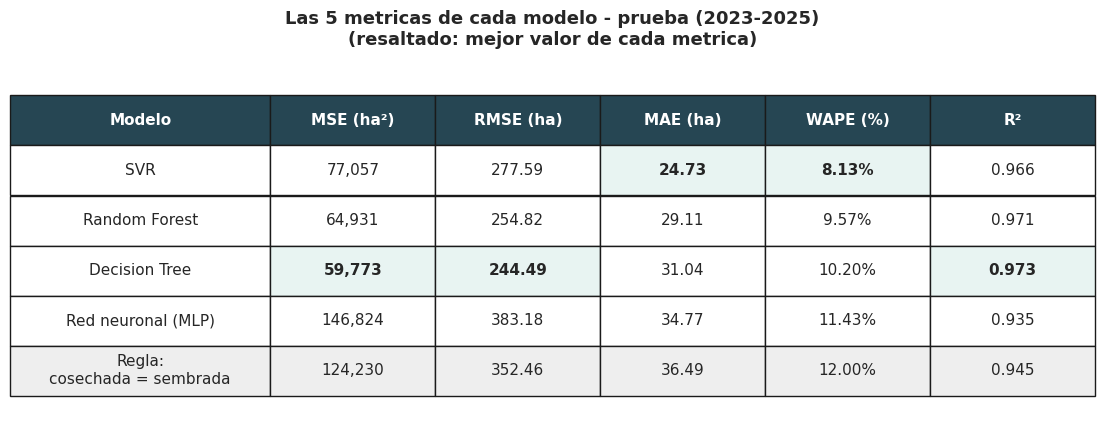

Guardada: tabla_metricas_modelos.png
PASO 3A: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO 3A: Tabla de las 5 metricas (prueba 2023-2025)
# =========================================================
print("PASO 3A: Tabla de las 5 metricas en prueba (2023-2025)")
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def cinco_metricas(real, estimada):
    mse = mean_squared_error(real, estimada)
    return {"MSE (ha²)": mse,
            "RMSE (ha)": np.sqrt(mse),
            "MAE (ha)": mean_absolute_error(real, estimada),
            "WAPE (%)": np.abs(real - estimada).sum() / real.sum() * 100,
            "R²": r2_score(real, estimada)}

filas = []
for m in MODELOS + [REGLA]:
    p = referencia if m == REGLA else predicciones[m]
    estimada = p["area_sembrada"].values.astype(float) if m == REGLA else p["area_cosechada_estimada"].values
    filas.append({"Modelo": m, **cinco_metricas(p["area_cosechada"].values, estimada)})

tabla_metricas = pd.DataFrame(filas).set_index("Modelo")
tabla_metricas = pd.concat([tabla_metricas.drop(index=REGLA).sort_values("WAPE (%)"),
                            tabla_metricas.loc[[REGLA]]])
print(tabla_metricas.round(3).to_string())
tabla_metricas.to_csv(RUTA + "tabla_metricas_modelos.csv")
print()
print("Guardada: tabla_metricas_modelos.csv")

# --- Tabla como imagen (para copiar y pegar en el informe) ---
formatos = {"MSE (ha²)": "{:,.0f}", "RMSE (ha)": "{:,.2f}", "MAE (ha)": "{:,.2f}",
            "WAPE (%)": "{:.2f}%", "R²": "{:.3f}"}
# Mejor valor de cada metrica entre los 4 modelos (menor error; mayor R²)
solo_modelos = tabla_metricas.drop(index=REGLA)
mejor = {c: (solo_modelos[c].max() if c == "R²" else solo_modelos[c].min()) for c in tabla_metricas.columns}

celdas = []
for modelo, fila in tabla_metricas.iterrows():
    celdas.append([modelo.replace(": ", ":\n")] + [formatos[c].format(fila[c]) for c in tabla_metricas.columns])

figura, ax = plt.subplots(figsize=(14, 1 + 0.8 * len(celdas)))
ax.axis("off")
tabla_img = ax.table(cellText=celdas, colLabels=["Modelo"] + list(tabla_metricas.columns),
                     loc="center", cellLoc="center", colWidths=[0.24] + [0.152] * 5)
tabla_img.auto_set_font_size(False)
tabla_img.set_fontsize(11)
tabla_img.scale(1, 3)
for (fila_i, col_i), celda in tabla_img.get_celld().items():
    if fila_i == 0:                                                   # encabezado
        celda.set_facecolor("#264653")
        celda.set_text_props(color="white", fontweight="bold")
    elif celdas[fila_i - 1][0].startswith("Regla"):                    # regla simple en gris
        celda.set_facecolor("#eeeeee")
    elif col_i > 0:
        columna = tabla_metricas.columns[col_i - 1]
        if tabla_metricas.iloc[fila_i - 1][columna] == mejor[columna]:  # mejor valor de la columna
            celda.set_facecolor("#e8f4f2")
            celda.set_text_props(fontweight="bold")
plt.title("Las 5 metricas de cada modelo - prueba (2023-2025)\n(resaltado: mejor valor de cada metrica)",
          fontsize=13, fontweight="bold")
plt.savefig(RUTA + "tabla_metricas_modelos.png", dpi=200, bbox_inches="tight")
plt.show()
print("Guardada: tabla_metricas_modelos.png")
print("PASO 3A: Ejecutado correctamente")
print("-------------------------------")

PASO 3B: Tabla general de comparacion
                                                                    Hiperparametros  WAPE validacion 2022  WAPE prueba 2023-2025  WAPE 2023  WAPE 2024  WAPE 2025
Modelo                                                                                                                                                           
SVR                                                  C=10, gamma=0.01, epsilon=0.01                  7.20                   8.13       7.18       9.24       8.00
Random Forest                n_estimators=300, min_samples_leaf=1, max_features=0.3                  8.01                   9.57       8.68      10.36       9.69
Decision Tree                    max_depth=16, min_samples_leaf=1, max_features=0.7                  9.13                  10.20       9.20      11.31      10.15
Red neuronal (MLP)                         hidden_layer_sizes=(128, 64), alpha=0.01                  8.85                  11.43      10.11      12.33  

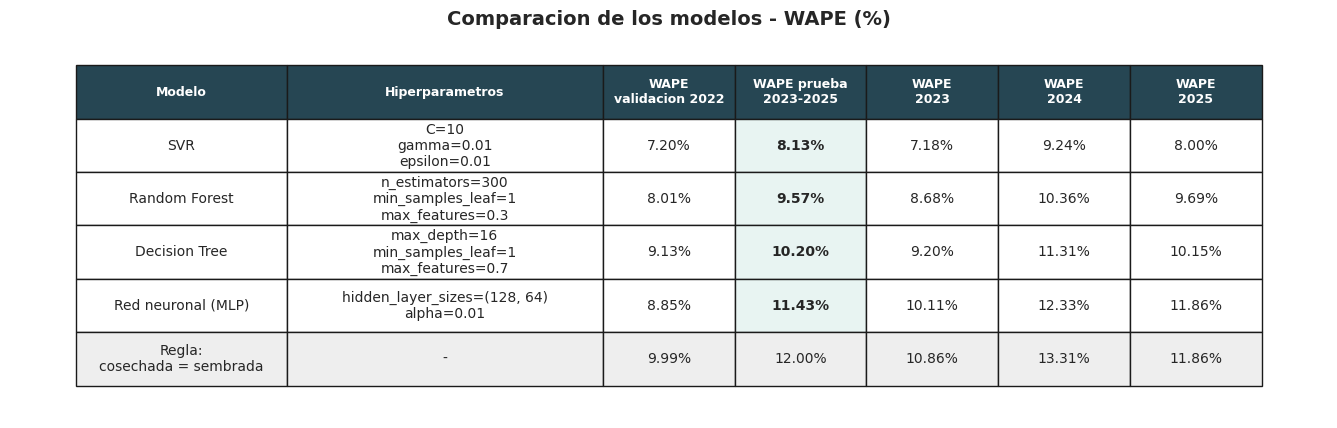

Guardada: tabla_comparacion_modelos.png
PASO 3B: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO 3B: Tabla general de comparacion (WAPE)
# =========================================================
print("PASO 3B: Tabla general de comparacion")

def wape(real, estimada):
    return np.abs(real - estimada).sum() / real.sum() * 100

# --- Hiperparametros elegidos por cada modelo (confirmar con cada companero) ---
HIPERPARAMETROS = {
    "Decision Tree": "max_depth=16, min_samples_leaf=1, max_features=0.7",
    "Random Forest": "n_estimators=300, min_samples_leaf=1, max_features=0.3",
    "Red neuronal (MLP)": "hidden_layer_sizes=(128, 64), alpha=0.01",
    "SVR": "C=10, gamma=0.01, epsilon=0.01",
}

# --- WAPE de validacion (2022) desde los archivos validacion_<modelo>.csv ---
WAPE_VALIDACION = {}
for m in MODELOS:
    v = pd.read_csv(RUTA + "validacion_" + m + ".csv", index_col=0 if m == "SVR" else None)
    if m == "SVR":
        # tabla de la Fase 2 del SVR: filas = metricas, columnas = conjuntos
        WAPE_VALIDACION[m] = v.loc["WAPE_%", "Validacion (2022)"]
        WAPE_VALIDACION[REGLA] = v.loc["WAPE_%", "Regla cosechada = sembrada (2022)"]
    else:
        # tabla de la busqueda de hiperparametros: se toma la mejor fila (menor WAPE)
        WAPE_VALIDACION[m] = v["WAPE_%"].min()

# --- Tabla: una fila por modelo y una para la regla simple ---
anios = sorted(referencia["anio"].unique())
filas = []
for m in MODELOS + [REGLA]:
    if m == REGLA:
        p = referencia
        estimada = p["area_sembrada"].values.astype(float)
    else:
        p = predicciones[m]
        estimada = p["area_cosechada_estimada"].values
    real = p["area_cosechada"].values
    fila = {"Modelo": m,
            "Hiperparametros": HIPERPARAMETROS.get(m, "-"),
            "WAPE validacion 2022": WAPE_VALIDACION.get(m),
            "WAPE prueba 2023-2025": wape(real, estimada)}
    for a in anios:
        mask = (p["anio"] == a).values
        fila["WAPE " + str(a)] = wape(real[mask], estimada[mask])
    filas.append(fila)

tabla_general = pd.DataFrame(filas).set_index("Modelo")
tabla_general = pd.concat([tabla_general.drop(index=REGLA).sort_values("WAPE prueba 2023-2025"),
                           tabla_general.loc[[REGLA]]])
print(tabla_general.round(2).to_string())
tabla_general.to_csv(RUTA + "tabla_comparacion_modelos.csv")
print()
print("Guardada: tabla_comparacion_modelos.csv")

# --- Tabla como imagen (para copiar y pegar en el informe) ---
import re
encabezados = ["Modelo", "Hiperparametros", "WAPE\nvalidacion 2022",
               "WAPE prueba\n2023-2025"] + ["WAPE\n" + str(a) for a in anios]
celdas = []
for modelo, fila in tabla_general.iterrows():
    hip = re.sub(r", (?=[a-zA-Z_])", "\n", fila["Hiperparametros"])   # un hiperparametro por linea
    nombre = modelo.replace(": ", ":\n")                             # nombre largo en dos lineas
    numeros = [fila[c] for c in tabla_general.columns[1:]]
    celdas.append([nombre, hip] + ["-" if pd.isna(v) else "{:.2f}%".format(v) for v in numeros])

figura, ax = plt.subplots(figsize=(17, 1 + 0.8 * len(celdas)))
ax.axis("off")
tabla_img = ax.table(cellText=celdas, colLabels=encabezados, loc="center", cellLoc="center",
                     colWidths=[0.16, 0.24] + [0.10] * (len(encabezados) - 2))
tabla_img.auto_set_font_size(False)
tabla_img.set_fontsize(10)
tabla_img.scale(1, 3.2)
for (fila_i, col_i), celda in tabla_img.get_celld().items():
    if fila_i == 0:                                                   # encabezado
        celda.set_facecolor("#264653")
        celda.set_text_props(color="white", fontweight="bold", fontsize=9)
    elif celdas[fila_i - 1][0].startswith("Regla"):                    # regla simple en gris
        celda.set_facecolor("#eeeeee")
    elif col_i == 3:                                                  # columna principal: prueba
        celda.set_facecolor("#e8f4f2")
        celda.set_text_props(fontweight="bold")
plt.title("Comparacion de los modelos - WAPE (%)", fontsize=14, fontweight="bold")
plt.savefig(RUTA + "tabla_comparacion_modelos.png", dpi=200, bbox_inches="tight")
plt.show()
print("Guardada: tabla_comparacion_modelos.png")
print("PASO 3B: Ejecutado correctamente")
print("-------------------------------")

PASO 4: Los 2 mejores modelos
1. SVR | WAPE prueba: 8.13 % | mejora sobre la regla simple: 32.2 %
2. Random Forest | WAPE prueba: 9.57 % | mejora sobre la regla simple: 20.2 %


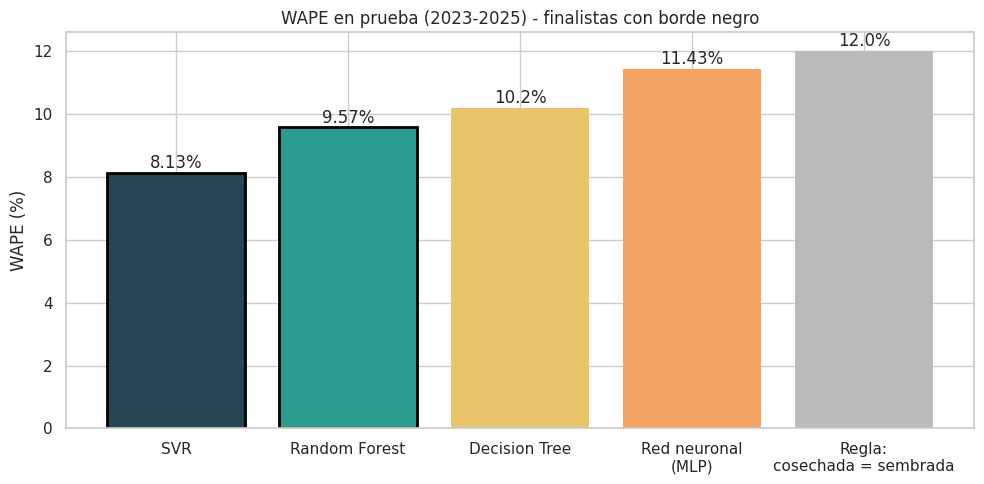

PASO 4: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO 4: Los 2 mejores modelos (menor WAPE en prueba 2023-2025)
# =========================================================
print("PASO 4: Los 2 mejores modelos")
solo_modelos = tabla_general.drop(index=REGLA)
FINALISTAS = list(solo_modelos["WAPE prueba 2023-2025"].nsmallest(2).index)
wape_regla = tabla_general.loc[REGLA, "WAPE prueba 2023-2025"]
for i, m in enumerate(FINALISTAS, 1):
    w = tabla_general.loc[m, "WAPE prueba 2023-2025"]
    print(str(i) + ".", m, "| WAPE prueba:", round(w, 2), "% | mejora sobre la regla simple:",
          round((wape_regla - w) / wape_regla * 100, 1), "%")

# Grafica: WAPE en prueba de los 4 modelos y la regla (los finalistas resaltados)
orden = list(solo_modelos.sort_values("WAPE prueba 2023-2025").index) + [REGLA]
valores = tabla_general.loc[orden, "WAPE prueba 2023-2025"]
plt.figure(figsize=(10, 5))
barras = plt.bar(orden, valores, color=[COLOR[m] for m in orden],
                 edgecolor=["black" if m in FINALISTAS else "none" for m in orden], linewidth=2)
for b, v in zip(barras, valores):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.15, str(round(v, 2)) + "%", ha="center")
plt.xticks(range(len(orden)), [m.replace(": ", ":\n").replace(" (", "\n(") for m in orden])
plt.ylabel("WAPE (%)")
plt.title("WAPE en prueba (2023-2025) - finalistas con borde negro")
plt.tight_layout()
plt.show()
print("PASO 4: Ejecutado correctamente")
print("-------------------------------")

## Gráficas detalladas de los 2 finalistas (prueba 2023–2025)

1. **WAPE por grupo de cultivo:** en qué cultivos funciona mejor cada modelo, frente a la regla simple.
2. **Área cosechada real vs estimada por grupo:** si algún modelo sobreestima o subestima un grupo.
3. **WAPE por año:** qué tan estable es cada modelo de un año a otro.

PASO 5: WAPE por grupo de cultivo


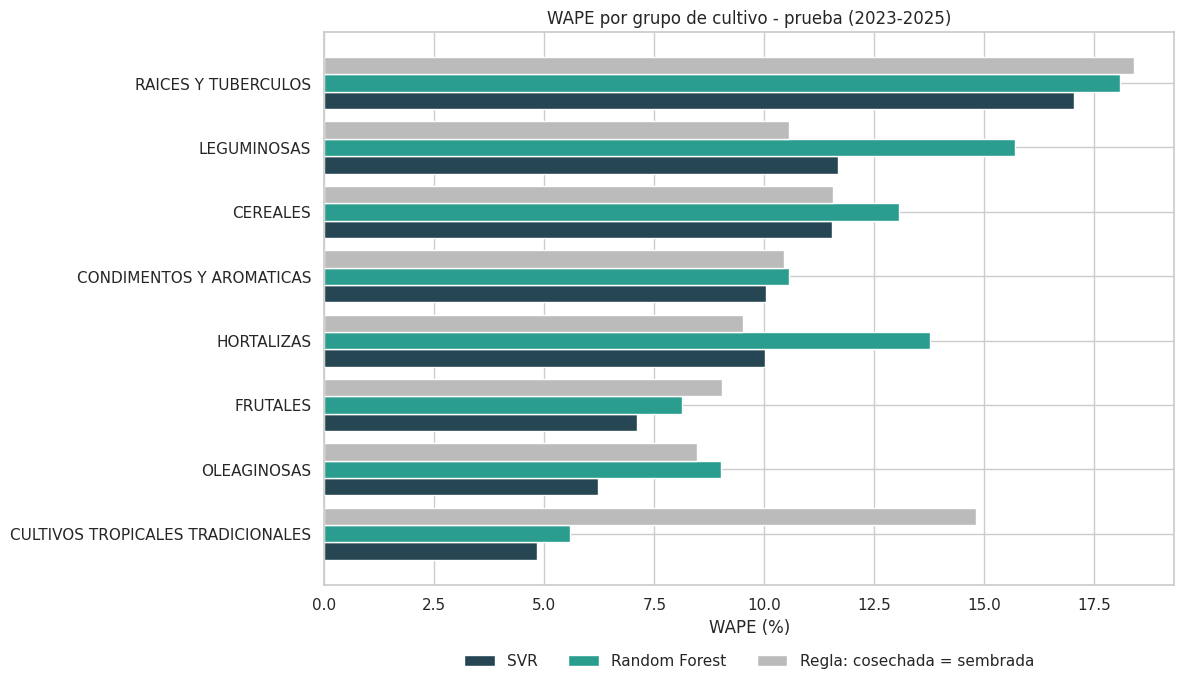

                                                              SVR  Random Forest  Regla: cosechada = sembrada
CULTIVOS TROPICALES TRADICIONALES                            4.82           5.57                        14.80
OLEAGINOSAS                                                  6.22           9.01                         8.46
FRUTALES                                                     7.11           8.12                         9.04
HORTALIZAS                                                  10.01          13.77                         9.51
CULTIVOS PARA CONDIMENTOS, BEBIDAS MEDICINALES Y AROMATICAS 10.04          10.55                        10.45
CEREALES                                                    11.54          13.05                        11.57
LEGUMINOSAS                                                 11.67          15.70                        10.56
RAICES Y TUBERCULOS                                         17.04          18.09                        18.39
PASO 5: Ej

In [ ]:
# =========================================================
# PASO 5: WAPE por grupo de cultivo (prueba 2023-2025)
# =========================================================
print("PASO 5: WAPE por grupo de cultivo")
grupos = sorted(referencia["grupo"].unique())
tabla_grupos = pd.DataFrame(index=grupos)
for m in FINALISTAS + [REGLA]:
    p = referencia if m == REGLA else predicciones[m]
    estimada = p["area_sembrada"].astype(float) if m == REGLA else p["area_cosechada_estimada"]
    tabla_grupos[m] = [wape(p.loc[p["grupo"] == g, "area_cosechada"].values,
                            estimada[p["grupo"] == g].values) for g in grupos]
tabla_grupos = tabla_grupos.sort_values(FINALISTAS[0])

y = np.arange(len(tabla_grupos))
alto = 0.27
plt.figure(figsize=(12, 7))
for i, m in enumerate(FINALISTAS + [REGLA]):
    plt.barh(y + (i - 1) * alto, tabla_grupos[m], alto, color=COLOR[m], label=m)
plt.yticks(y, [corto(g) for g in tabla_grupos.index])
plt.xlabel("WAPE (%)")
plt.title("WAPE por grupo de cultivo - prueba (2023-2025)")
plt.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.tight_layout()
plt.show()
print(tabla_grupos.round(2).to_string())
print("PASO 5: Ejecutado correctamente")
print("-------------------------------")

PASO 6: Area cosechada real vs estimada por grupo


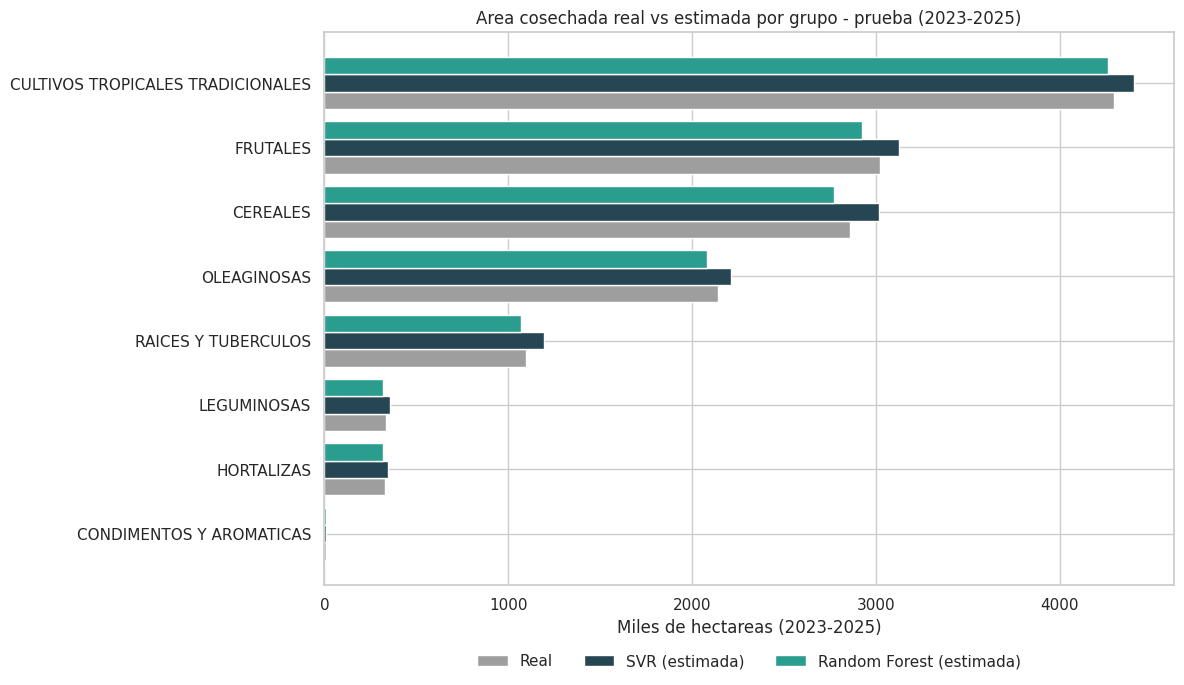

Diferencia estimada vs real (%): + sobreestima, - subestima
                                                             SVR  Random Forest
grupo                                                                          
CULTIVOS PARA CONDIMENTOS, BEBIDAS MEDICINALES Y AROMATICAS 5.93          -3.86
HORTALIZAS                                                  4.14          -4.58
LEGUMINOSAS                                                 5.89          -5.49
RAICES Y TUBERCULOS                                         9.11          -2.39
OLEAGINOSAS                                                 3.40          -2.89
CEREALES                                                    5.40          -3.14
FRUTALES                                                    3.42          -3.23
CULTIVOS TROPICALES TRADICIONALES                           2.43          -0.77
PASO 6: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO 6: Area cosechada real vs estimada por grupo (prueba 2023-2025)
# =========================================================
print("PASO 6: Area cosechada real vs estimada por grupo")
tabla_area = pd.DataFrame({"Real": referencia.groupby("grupo")["area_cosechada"].sum()})
for m in FINALISTAS:
    tabla_area[m] = predicciones[m].groupby("grupo")["area_cosechada_estimada"].sum()
tabla_area = tabla_area.sort_values("Real") / 1000          # miles de hectareas

y = np.arange(len(tabla_area))
alto = 0.27
plt.figure(figsize=(12, 7))
plt.barh(y - alto, tabla_area["Real"], alto, color="#9e9e9e", label="Real")
for i, m in enumerate(FINALISTAS):
    plt.barh(y + i * alto, tabla_area[m], alto, color=COLOR[m], label=m + " (estimada)")
plt.yticks(y, [corto(g) for g in tabla_area.index])
plt.xlabel("Miles de hectareas (2023-2025)")
plt.title("Area cosechada real vs estimada por grupo - prueba (2023-2025)")
plt.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.tight_layout()
plt.show()

diferencia = tabla_area[FINALISTAS].sub(tabla_area["Real"], axis=0).div(tabla_area["Real"], axis=0) * 100
print("Diferencia estimada vs real (%): + sobreestima, - subestima")
print(diferencia.round(2).to_string())
print("PASO 6: Ejecutado correctamente")
print("-------------------------------")

PASO 7: WAPE por año


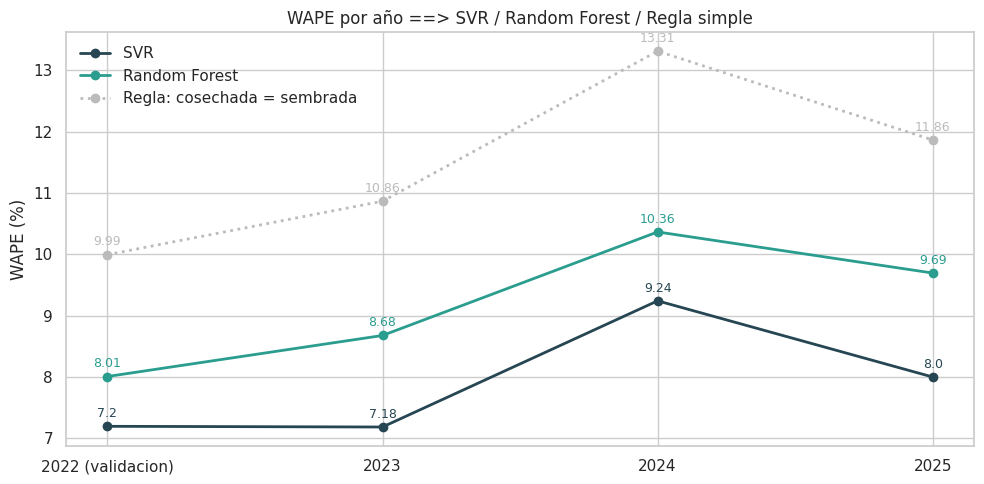

                             WAPE validacion 2022  WAPE 2023  WAPE 2024  WAPE 2025
Modelo                                                                            
SVR                                          7.20       7.18       9.24       8.00
Random Forest                                8.01       8.68      10.36       9.69
Regla: cosechada = sembrada                  9.99      10.86      13.31      11.86
PASO 7: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO 7: WAPE por anio (validacion 2022 y prueba 2023-2025)
# =========================================================
print("PASO 7: WAPE por año")
etiquetas = ["2022 (validacion)"] + [str(a) for a in anios]
plt.figure(figsize=(10, 5))
for m in FINALISTAS + [REGLA]:
    valores = [tabla_general.loc[m, "WAPE validacion 2022"]] + \
              [tabla_general.loc[m, "WAPE " + str(a)] for a in anios]
    plt.plot(etiquetas, valores, marker="o", linewidth=2, color=COLOR[m], label=m,
             linestyle=":" if m == REGLA else "-")
    for x, v in zip(etiquetas, valores):
        plt.text(x, v + 0.15, str(round(v, 2)), ha="center", fontsize=9, color=COLOR[m])
plt.ylabel("WAPE (%)")
plt.title("WAPE por año ==> SVR / Random Forest / Regla simple")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()
print(tabla_general.loc[FINALISTAS + [REGLA], ["WAPE validacion 2022"] + ["WAPE " + str(a) for a in anios]].round(2).to_string())
print("PASO 7: Ejecutado correctamente")
print("-------------------------------")

In [ ]:
# =========================================================
# PASO 8: Preparar los datos de permanentes y transitorios
# =========================================================
print("PASO 8: Preparar los datos de permanentes y transitorios")
RUTA_EVA = "/content/drive/MyDrive/EVA/"

# Tabla limpia completa (2007-2025): para ver la historia de cada cultivo
limpio = pd.read_csv(RUTA_EVA + "eva_limpio.csv", dtype={"cod_mun": str, "cod_dep": str})
limpio["area_disponible"] = limpio["area_sembrada"] + limpio["area_pendiente_anterior"].fillna(0)

# Ciclo de cada cultivo (cada cultivo es siempre permanente o siempre transitorio)
ciclo_cultivo = limpio.drop_duplicates("cultivo").set_index("cultivo")["ciclo"]

# Tabla base de la prueba: datos reales + ciclo + estimacion de cada modelo
base = predicciones["SVR"][CLAVE + ["municipio", "grupo", "area_sembrada", "area_disponible", "area_cosechada"]].copy()
base["ciclo"] = base["cultivo"].map(ciclo_cultivo)
for m in MODELOS:
    base[m] = predicciones[m]["area_cosechada_estimada"].values   # mismas filas y mismo orden (PASO 2)

# Segunda regla simple: "cosechada = la cosechada del anio anterior"
anterior = limpio[CLAVE + ["area_cosechada"]].copy()
anterior["anio"] = anterior["anio"] + 1
anterior = anterior.rename(columns={"area_cosechada": "cosechada_anio_anterior"})
base = base.merge(anterior, on=CLAVE, how="left")
REGLA_ANT = "Regla: cosechada = la del anio anterior"
base[REGLA_ANT] = base["cosechada_anio_anterior"].fillna(base["area_sembrada"]).clip(upper=base["area_disponible"])
base[REGLA] = base["area_sembrada"]
COLOR[REGLA_ANT] = "#8d99ae"

print("Filas de prueba:", len(base), "| sin ciclo:", base["ciclo"].isna().sum())
print(base["ciclo"].value_counts().to_string())
print("PASO 8: Ejecutado correctamente")
print("-------------------------------")

PASO 8: Preparar los datos de permanentes y transitorios
Filas de prueba: 46334 | sin ciclo: 0
ciclo
PERMANENTE     26987
TRANSITORIO    19347
PASO 8: Ejecutado correctamente
-------------------------------


PASO 9: WAPE de permanentes y transitorios
                                              PERMANENTE  TRANSITORIO
% de las hectareas                                 65.29        34.71
% cosechado real                                   89.52        82.68
WAPE SVR                                            5.86        12.39
WAPE Random Forest                                  6.60        15.16
WAPE Regla: cosechada = sembrada                   11.70        12.55
WAPE Regla: cosechada = la del anio anterior        4.59        18.40


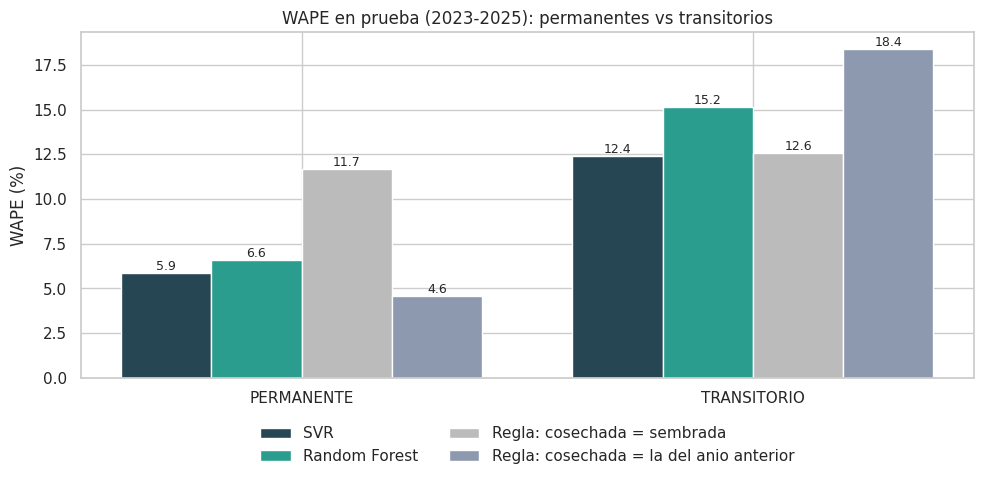

PASO 9: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO 9: WAPE de permanentes y transitorios (prueba 2023-2025)
# =========================================================
print("PASO 9: WAPE de permanentes y transitorios")
COMPARAR = FINALISTAS + [REGLA, REGLA_ANT]

filas = {}
for ciclo, g in base.groupby("ciclo"):
    fila = {"% de las hectareas": g["area_cosechada"].sum() / base["area_cosechada"].sum() * 100,
            "% cosechado real": g["area_cosechada"].sum() / g["area_disponible"].sum() * 100}
    for m in COMPARAR:
        fila["WAPE " + m] = wape(g["area_cosechada"], g[m])
    filas[ciclo] = fila
tabla_ciclo = pd.DataFrame(filas).T
print(tabla_ciclo.round(2).T.to_string())

# Grafica: barras agrupadas (un grupo de barras por ciclo)
x = np.arange(len(tabla_ciclo))
ancho = 0.8 / len(COMPARAR)
plt.figure(figsize=(10, 5))
for i, m in enumerate(COMPARAR):
    valores = tabla_ciclo["WAPE " + m]
    barras = plt.bar(x + i * ancho, valores, ancho, color=COLOR[m], label=m)
    plt.bar_label(barras, fmt="%.1f", fontsize=9)
plt.xticks(x + ancho * (len(COMPARAR) - 1) / 2, tabla_ciclo.index)
plt.ylabel("WAPE (%)")
plt.title("WAPE en prueba (2023-2025): permanentes vs transitorios")
plt.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()
plt.show()
print("PASO 9: Ejecutado correctamente")
print("-------------------------------")

PASO 10: Porcentaje cosechado por anio


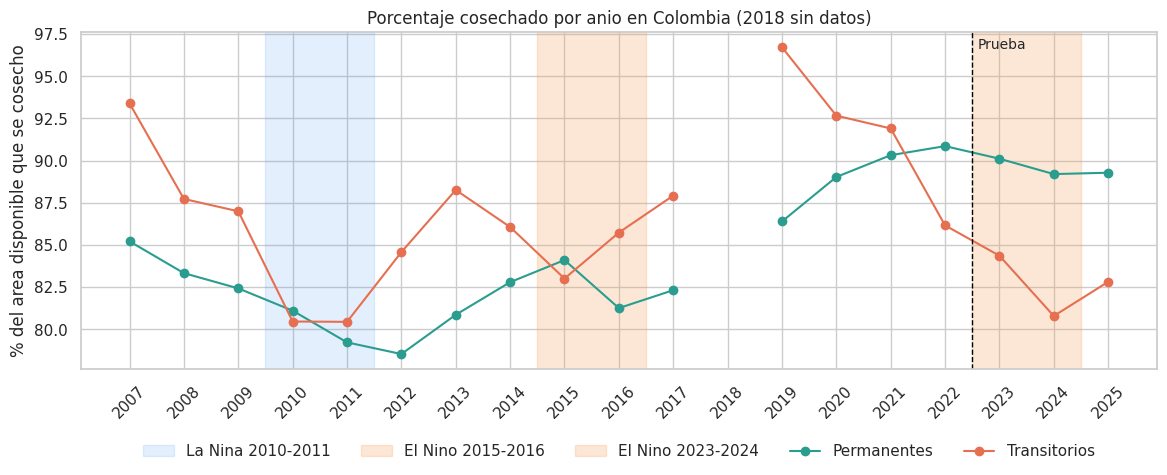

anio         2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2019  2020  2021  2022  2023  2024  2025
ciclo                                                                                                                  
PERMANENTE  85.20 83.30 82.40 81.10 79.20 78.50 80.90 82.80 84.10 81.20 82.30 86.40 89.00 90.30 90.90 90.10 89.20 89.30
TRANSITORIO 93.40 87.70 87.00 80.50 80.40 84.60 88.30 86.10 83.00 85.70 87.90 96.70 92.70 91.90 86.20 84.40 80.80 82.80

Transitorios: area NO cosechada en el anio y cuanto pasa como pendiente al anio siguiente
      no_cosechado  pasa_al_anio_siguiente  % que se cosecha al anio siguiente
anio                                                                          
2007    125,989.00              124,055.00                               98.50
2008    253,844.00              126,804.00                               50.00
2009    267,926.00              138,691.00                               51.80
2010    401,278.00              25

In [ ]:
# =========================================================
# PASO 10: Porcentaje cosechado en Colombia por anio (2007-2025)
# =========================================================
print("PASO 10: Porcentaje cosechado por anio")
anual = limpio.groupby(["anio", "ciclo"])[["area_cosechada", "area_disponible"]].sum()
anual = (anual["area_cosechada"] / anual["area_disponible"] * 100).unstack()
anual = anual.reindex(range(2007, 2026))          # 2018 queda vacio (no hay datos) y corta la linea

plt.figure(figsize=(12, 5))
plt.axvspan(2009.5, 2011.5, color="#4895ef", alpha=0.15, label="La Nina 2010-2011")
plt.axvspan(2014.5, 2016.5, color="#f4a261", alpha=0.25, label="El Nino 2015-2016")
plt.axvspan(2022.5, 2024.5, color="#f4a261", alpha=0.25, label="El Nino 2023-2024")
plt.plot(anual.index, anual["PERMANENTE"], marker="o", color="#2a9d8f", label="Permanentes")
plt.plot(anual.index, anual["TRANSITORIO"], marker="o", color="#e76f51", label="Transitorios")
plt.axvline(2022.5, color="black", linestyle="--", linewidth=1)
plt.text(2022.6, plt.ylim()[1] - 1, "Prueba", fontsize=10)
plt.xticks(range(2007, 2026), rotation=45)
plt.ylabel("% del area disponible que se cosecho")
plt.title("Porcentaje cosechado por anio en Colombia (2018 sin datos)")
plt.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=5)
plt.tight_layout()
plt.show()
print(anual.dropna().round(1).T.to_string())

# En transitorios: lo que no se cosecha en un anio, cuanto aparece como "pendiente" el anio siguiente?
CLAVE_SERIE = ["cod_mun", "cultivo", "estado_fisico"]
siguiente = limpio[CLAVE_SERIE + ["anio", "area_pendiente_anterior"]].copy()
siguiente["anio"] = siguiente["anio"] - 1
siguiente = siguiente.rename(columns={"area_pendiente_anterior": "pasa_al_anio_siguiente"})
trans = limpio[limpio["ciclo"] == "TRANSITORIO"].merge(siguiente, on=CLAVE_SERIE + ["anio"], how="left")
trans["no_cosechado"] = trans["area_disponible"] - trans["area_cosechada"]
corrido = trans.groupby("anio")[["no_cosechado", "pasa_al_anio_siguiente"]].sum()
corrido = corrido.drop([2017, 2025])               # sin anio siguiente con datos (2018 y 2026)
corrido["% que se cosecha al anio siguiente"] = corrido["pasa_al_anio_siguiente"] / corrido["no_cosechado"] * 100
print()
print("Transitorios: area NO cosechada en el anio y cuanto pasa como pendiente al anio siguiente")
print(corrido.round(1).to_string())
print("PASO 10: Ejecutado correctamente")
print("-------------------------------")

PASO 11: Dos ejemplos
Permanente - CAFE en Pitalito (Huila)
anio                      2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   2019   2020   2021   2022   2023   2024   2025
area_sembrada            11316  12279  12850  14945  16855  18536  20465  20154  19821  19119  18508  18291  19015  17513  17642  17753  17790  17761
area_pendiente_anterior      0      0      0      0      0      0      0      0      0      0      0      0      0      0      0      0      0      0
area_cosechada           10733  10882  10607  11226   9789  10275  16178  17125  16847  15931  15477  14195  18454  13828  14437  14718  13763  13327
% cosechado                 95     89     83     75     58     55     79     85     85     83     84     78     97     79     82     83     77     75

Transitorio - ARROZ en Arauca (Arauca)
anio                     2007  2008  2009  2010  2011  2012  2013  2014  2015   2016   2017   2019   2020   2021   2022   2023   2024   2025
area_semb

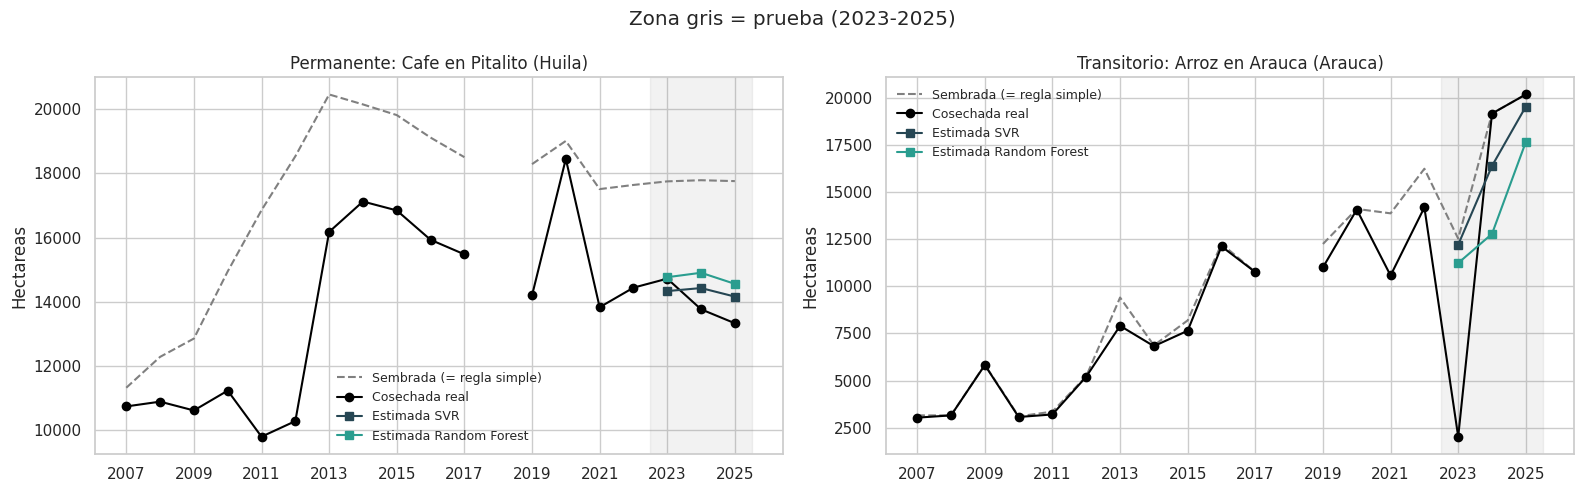

PASO 11: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO 11: Dos ejemplos (un permanente y un transitorio)
# =========================================================
print("PASO 11: Dos ejemplos")
EJEMPLOS = [("41551", "CAFE", "Permanente"),        # Pitalito (Huila)
            ("81001", "ARROZ", "Transitorio")]      # Arauca (Arauca)

figura, ejes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (cod, cultivo, tipo) in zip(ejes, EJEMPLOS):
    # Historia real (se suman los estados fisicos del mismo cultivo en cada anio)
    h = limpio[(limpio["cod_mun"] == cod) & (limpio["cultivo"] == cultivo)]
    nombre = h["municipio"].iloc[0].title() + " (" + h["departamento"].iloc[0].title() + ")"
    h = h.groupby("anio")[["area_sembrada", "area_pendiente_anterior", "area_cosechada"]].sum().reindex(range(2007, 2026))
    # Estimaciones de los finalistas en la prueba
    e = base[(base["cod_mun"] == cod) & (base["cultivo"] == cultivo)].groupby("anio")[FINALISTAS].sum()

    ax.axvspan(2022.5, 2025.5, color="gray", alpha=0.1)
    ax.plot(h.index, h["area_sembrada"], linestyle="--", color="gray", label="Sembrada (= regla simple)")
    ax.plot(h.index, h["area_cosechada"], marker="o", color="black", label="Cosechada real")
    for m in FINALISTAS:
        ax.plot(e.index, e[m], marker="s", color=COLOR[m], label="Estimada " + m)
    ax.set_xticks(range(2007, 2026, 2))
    ax.set_ylabel("Hectareas")
    ax.set_title(tipo + ": " + cultivo.title() + " en " + nombre)
    ax.legend(frameon=False, fontsize=9)

    h["% cosechado"] = h["area_cosechada"] / h["area_sembrada"] * 100
    print(tipo, "-", cultivo, "en", nombre)
    print(h.dropna().round(0).astype(int).T.to_string())
    print()
plt.suptitle("Zona gris = prueba (2023-2025)")
plt.tight_layout()
plt.show()
print("PASO 11: Ejecutado correctamente")
print("-------------------------------")